# Étape 16 : tutoriel PyTorch, la régression logistique refaite en réseau de neurones

**PyTorch** est une bibliothèque de *deep learning* (réseaux de neurones). Elle fait trois choses :
1. elle calcule sur des **tenseurs**, des tableaux de nombres comme ceux de numpy ;
2. elle calcule **toute seule les gradients** (*autograd*) : de combien la perte change quand
   on bouge chaque poids, donc dans quel sens corriger le modèle ;
3. elle fournit les briques toutes prêtes : couches (`nn.Linear`, `nn.GRU`…), fonctions de
   perte, optimiseurs.

**Pourquoi ici ?** Le prochain modèle du plan est un **GRU** qui lit une partie minute par minute.
scikit-learn ne sait pas faire ça. Mais avec PyTorch, on écrit soi-même la boucle d'entraînement :
avant d'attaquer le GRU, on apprend cette boucle sur un problème **dont on connaît déjà la réponse**.
La régression logistique de l'étape 13 obtient une log loss de **0,524** sur le test : si notre
version PyTorch retrouve ce chiffre, la boucle est juste.

Plan :
1. Les tenseurs
2. L'autograd : les gradients calculés tout seuls
3. Les données (les mêmes qu'aux étapes 13 à 15)
4. La régression logistique « à la main »
5. La même avec les briques de PyTorch : `nn.Module`, optimiseur, mini-lots, arrêt précoce
6. Un vrai réseau de neurones (MLP) : fait-il mieux que la logistique ?
7. Aperçu du GRU : des données en 3 dimensions
8. Conclusions

## 1. Les tenseurs

Un tenseur, c'est un tableau numpy « amélioré » : mêmes opérations, mais PyTorch peut retenir
comment chaque nombre a été calculé (pour l'autograd) et le placer sur une carte graphique. Ici,
pas de carte graphique NVIDIA : tout tourne sur le processeur (CPU), largement assez pour nos
~4 800 parties.

Le vocabulaire à retenir : **shape** (la forme, ex. `(3, 2)` = 3 lignes, 2 colonnes) et
**dtype** (le type des nombres : PyTorch travaille en `float32`, deux fois moins précis
que le `float64` de numpy, mais largement suffisant et plus rapide).

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from torch import nn

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

pd.set_option("display.width", 120)
plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.grid": True, "grid.alpha": 0.3})
print("PyTorch", torch.__version__, "| carte graphique CUDA :", torch.cuda.is_available())

a = torch.tensor([[1.0, 2.0], [3.0, 4.0], [5.0, 6.0]])
print("a =", a, "\nshape :", a.shape, "| dtype :", a.dtype)
print("a * 10 =", a * 10)                       # opération case par case
print("moyenne par colonne :", a.mean(dim=0))   # dim=0 : on écrase les lignes
w = torch.tensor([0.5, -1.0])
print("a @ w =", a @ w)                         # produit matriciel : une valeur par ligne
print("depuis numpy :", torch.from_numpy(np.array([1.5, 2.5])), "| vers numpy :", a.numpy()[0])

PyTorch 2.14.1+cpu | carte graphique CUDA : False
a = tensor([[1., 2.],
        [3., 4.],
        [5., 6.]]) 
shape : torch.Size([3, 2]) | dtype : torch.float32
a * 10 = tensor([[10., 20.],
        [30., 40.],
        [50., 60.]])
moyenne par colonne : tensor([3., 4.])
a @ w = tensor([-1.5000, -2.5000, -3.5000])
depuis numpy : tensor([1.5000, 2.5000], dtype=torch.float64) | vers numpy : [1. 2.]


`a @ w` est exactement ce que fait une régression logistique : pour chaque partie (ligne), la
somme pondérée de ses variables. Tout le reste du notebook est construit sur cette opération.

## 2. L'autograd : les gradients calculés tout seuls

Entraîner un modèle, c'est chercher les poids qui rendent la **perte** (l'erreur) la plus petite
possible. La méthode : la **descente de gradient**. On calcule le gradient (la pente de la perte
par rapport à chaque poids) puis on fait un petit pas dans le sens qui descend, et on recommence.

Exemple jouet : on cherche `w` tel que `3 × w = 9`. Perte = `(3w − 9)²`, minimale en `w = 3`.
On marque `w` avec `requires_grad=True` : PyTorch enregistre les calculs faits avec lui, et
`loss.backward()` remonte ces calculs pour obtenir le gradient dans `w.grad`.
À la main : dérivée = `2 × (3w − 9) × 3`, soit **−18** en `w = 2`. PyTorch doit trouver pareil.

In [2]:
w = torch.tensor(2.0, requires_grad=True)
loss = (3 * w - 9) ** 2
loss.backward()
print(f"perte = {loss.item():.1f}, gradient = {w.grad.item():.1f} (attendu : -18)")

# Descente de gradient : 15 petits pas « contre la pente »
lr = 0.02  # le taux d'apprentissage (learning rate) : la taille du pas
for step in range(1, 16):
    w.grad = None                  # effacer l'ancien gradient (sinon PyTorch les additionne)
    loss = (3 * w - 9) ** 2
    loss.backward()
    with torch.no_grad():          # la correction elle-même ne doit pas être enregistrée
        w -= lr * w.grad
    if step in (1, 2, 5, 10, 15):
        print(f"pas {step:2d} : w = {w.item():.4f}, perte = {loss.item():.4f}")

perte = 9.0, gradient = -18.0 (attendu : -18)
pas  1 : w = 2.3600, perte = 9.0000
pas  2 : w = 2.5904, perte = 3.6864
pas  5 : w = 2.8926, perte = 0.2533
pas 10 : w = 2.9885, perte = 0.0029
pas 15 : w = 2.9988, perte = 0.0000


`w` s'approche de 3 et la perte de 0. Un réseau de neurones, c'est la même chose avec des
milliers de poids au lieu d'un seul : PyTorch calcule tous les gradients d'un coup.

## 3. Les données

Mêmes données et même découpage qu'aux étapes 13 à 15 : les 11 variables à 15 min, et le test =
les 20 % de parties les plus récentes. Avant de lancer : **Docker Desktop ouvert et
`docker compose start` fait.**

Les variables sont **centrées-réduites** (moyenne 0, écart type 1) avec un `StandardScaler`
appris sur l'entraînement seulement, comme dans `make_logit()`. Pour un réseau c'est encore plus
important que pour la logistique : la descente de gradient avance mal quand une variable vaut
des milliers et une autre des dixièmes (les pas sont trop grands pour l'une, trop petits pour
l'autre).

In [3]:
from sklearn.preprocessing import StandardScaler

from deep import MLP, LogisticNet, TorchClassifier, predict_proba, set_seed, to_tensor, train_model
from features import FEATURES, TARGET, build_features, time_split
from models import cross_validate, evaluate, fit_predict, make_logit, paired_bootstrap

warnings.filterwarnings("ignore", message="X does not have valid feature names")

df = build_features()
train, test = time_split(df, test_frac=0.2)
scaler = StandardScaler().fit(train[FEATURES])
X_train = to_tensor(scaler.transform(train[FEATURES]))
y_train = to_tensor(train[TARGET])
X_test = to_tensor(scaler.transform(test[FEATURES]))
y_test = test[TARGET].to_numpy()
print(f"{len(df)} parties : {len(train)} entraînement, {len(test)} test")
print("X_train :", tuple(X_train.shape), X_train.dtype, "| y_train :", tuple(y_train.shape))

# La référence à retrouver : la logistique de scikit-learn (étape 13)
p_sk, logit_sk = fit_predict(make_logit, FEATURES, train, test)
ref = evaluate(y_test, p_sk)
print(f"Référence scikit-learn, log loss test = {ref['log_loss']:.4f} (étape 13 : 0.5242)")

4762 parties : 3809 entraînement, 953 test
X_train : (3809, 11) torch.float32 | y_train : (3809,)
Référence scikit-learn, log loss test = 0.5242 (étape 13 : 0.5242)


## 4. La régression logistique « à la main »

Le modèle : `logit = X @ w + b`, puis probabilité = `sigmoïde(logit)`. La perte : la
**log loss** (en PyTorch, *binary cross-entropy*, BCE), la même que celle qu'on mesure depuis
l'étape 11.

Pour retrouver **exactement** scikit-learn, il faut aussi sa pénalité L2 : avec `C = 1`,
scikit-learn minimise « log loss moyenne + ‖w‖² / (2 × C × n) » (n = nombre de parties).
On l'ajoute à la perte. Puis descente de gradient sur toutes les parties à la fois, 2 000 pas.

Si tout est juste, les 11 coefficients doivent être ceux de scikit-learn, à quelques millièmes près.

In [4]:
set_seed()
n, k = X_train.shape
w = torch.zeros(k, requires_grad=True)
b = torch.zeros(1, requires_grad=True)
lam = 1 / (1.0 * n)  # pénalité de scikit-learn avec C = 1
bce = nn.BCEWithLogitsLoss()  # sigmoïde + log loss en une fois (plus stable, voir deep.py)

losses = []
for step in range(2000):
    w.grad, b.grad = None, None
    loss = bce(X_train @ w + b, y_train) + lam * (w ** 2).sum() / 2
    loss.backward()
    with torch.no_grad():
        w -= 1.0 * w.grad
        b -= 1.0 * b.grad
    losses.append(loss.item())

coefs = pd.DataFrame({"PyTorch à la main": w.detach().numpy(),
                      "scikit-learn": logit_sk[-1].coef_[0]}, index=FEATURES)
coefs["écart"] = coefs["PyTorch à la main"] - coefs["scikit-learn"]
print(f"perte après 1, 100, 2000 pas : {losses[0]:.4f}, {losses[99]:.4f}, {losses[-1]:.4f}")
print(f"plus grand écart de coefficient : {coefs['écart'].abs().max():.4f}")
display(coefs.round(4))

p_hand = torch.sigmoid(X_test @ w + b).detach().numpy()
print(f"log loss test : à la main {evaluate(y_test, p_hand)['log_loss']:.4f} | "
      f"scikit-learn {ref['log_loss']:.4f}")

perte après 1, 100, 2000 pas : 0.6931, 0.5244, 0.5236
plus grand écart de coefficient : 0.0018


,PyTorch à la main,scikit-learn,écart
gold_k,1.0895,1.0879,0.0016
xp_k,0.3581,0.3583,-0.0001
cs_diff,-0.0949,-0.0937,-0.0013
kills_diff,-0.0872,-0.0854,-0.0018
towers_diff,-0.0675,-0.0673,-0.0003
plates_diff,0.0896,0.0896,-0.0000
dragons_diff,0.4886,0.4888,-0.0002
grubs_diff,0.1045,0.1051,-0.0006
first_blood,-0.0212,-0.0211,-0.0001
first_tower,-0.0085,-0.0098,0.0013


log loss test : à la main 0.5242 | scikit-learn 0.5242


Les coefficients et la log loss sont ceux de scikit-learn : **la logistique n'est qu'un réseau de
neurones à une seule couche, sans couche cachée**. scikit-learn utilise simplement un algorithme
plus malin que nos 2 000 petits pas (lbfgs) pour arriver au même point.

## 5. La même chose avec les briques de PyTorch

En pratique on n'écrit pas `w` et `b` à la main. On utilise la recette standard, la même pour
tous les réseaux, du plus petit jusqu'au GRU :

| Brique | Rôle | Ici |
|---|---|---|
| `nn.Module` | le modèle : ses couches et son calcul (`forward`) | `LogisticNet` : une couche `nn.Linear(11, 1)` |
| fonction de perte | mesurer l'erreur | `nn.BCEWithLogitsLoss` (log loss) |
| optimiseur | corriger les poids à partir des gradients | `AdamW` : une descente de gradient qui adapte la taille du pas à chaque poids |
| `DataLoader` | découper les parties en **mini-lots** mélangés | 128 parties par lot |

La boucle, dans `train_model()` (`src/deep.py`), tient en 4 lignes répétées pour chaque mini-lot :
`zero_grad()` (effacer) → `loss_fn(model(xb), yb)` (prédire et mesurer) → `backward()` (gradients)
→ `step()` (corriger). Un passage sur toutes les parties s'appelle une **époque**.

**Pourquoi des mini-lots ?** Corriger les poids après 128 parties plutôt qu'après toutes :
beaucoup plus de corrections par époque, et indispensable quand les données ne tiennent pas en
mémoire (ce sera le cas des séquences du GRU, plus grosses).

**L'arrêt précoce.** Un réseau peut apprendre le bruit de l'entraînement (surapprentissage). On
met donc de côté les 15 % de parties d'entraînement les plus récentes comme **validation** : après
chaque époque on y mesure la perte, on garde les poids de la meilleure époque, et on s'arrête
quand elle ne s'améliore plus depuis 20 époques. Le test, lui, reste intact.

LogisticNet(
  (linear): Linear(in_features=11, out_features=1, bias=True)
)
poids appris : 12 (11 coefficients + 1 constante)
époque  10  train 0.5251  valid 0.5243
époque  20  train 0.5242  valid 0.5247
époque  30  train 0.5239  valid 0.5235
meilleure époque : 12 sur 32


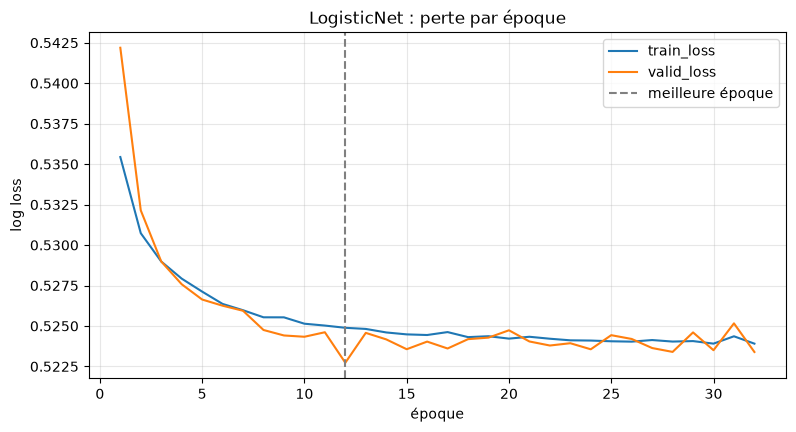

log loss test : LogisticNet 0.5243 | scikit-learn 0.5242


In [5]:
cut = int(len(X_train) * 0.85)  # les lignes sont triées par date : la validation = les plus récentes
fit_set, valid_set = (X_train[:cut], y_train[:cut]), (X_train[cut:], y_train[cut:])

set_seed()
net = LogisticNet(len(FEATURES))
print(net)
print("poids appris :", sum(p.numel() for p in net.parameters()), "(11 coefficients + 1 constante)")
history = train_model(net, fit_set, valid_set, lr=1e-2, verbose=True)
best = history.attrs["best_epoch"]
print(f"meilleure époque : {best} sur {len(history)}")

ax = history.plot(x="epoch", y=["train_loss", "valid_loss"])
ax.axvline(best, color="grey", ls="--", label="meilleure époque")
ax.set(xlabel="époque", ylabel="log loss", title="LogisticNet : perte par époque")
ax.legend()
plt.show()

p_net = predict_proba(net, X_test)
print(f"log loss test : LogisticNet {evaluate(y_test, p_net)['log_loss']:.4f} | "
      f"scikit-learn {ref['log_loss']:.4f}")

À lire sur la courbe : la perte baisse vite les premières époques puis se stabilise. Pour une
logistique, l'écart entre entraînement et validation reste à peu près constant : pas de vrai
surapprentissage avec 12 poids pour ~3 200 parties (l'écart vient surtout de ce que la validation,
ce sont des parties plus récentes). La log loss test doit être très proche de 0,524 ; un petit écart est normal, car ce
modèle n'a vu que 85 % de l'entraînement (le reste sert à l'arrêt précoce) et n'a pas exactement
la même pénalité.

## 6. Un vrai réseau de neurones : fait-il mieux ?

Le **MLP** (perceptron multicouche) ajoute une **couche cachée** entre les variables et la
sortie : 16 neurones, chacun une combinaison des 11 variables passée dans une fonction **ReLU**
(`max(0, x)`). Ce coude permet de représenter des effets non linéaires (« 1 000 d'or d'avance
compte plus quand… ») et des interactions entre variables, ce que la logistique ne sait pas
faire. Contre le surapprentissage : **dropout** (20 % des neurones éteints au hasard à chaque
mini-lot) et **weight decay** (pénalité L2, comme le C de la logistique).

Pour comparer honnêtement, on réutilise **la validation croisée chronologique de l'étape 13**
(`cross_validate`, 5 plis, sur l'entraînement seulement). C'est possible grâce à
`TorchClassifier` : une enveloppe qui donne au réseau les méthodes `fit` / `predict_proba` de
scikit-learn. Dans chaque pli, le scaler et l'arrêt précoce n'utilisent que l'entraînement du pli.

Compter environ 1 à 3 minutes.

In [6]:
candidates = {
    "Logit (scikit-learn)": make_logit,
    "Logit (PyTorch)": lambda: TorchClassifier(LogisticNet),
    "MLP 16 neurones": lambda: TorchClassifier(lambda n: MLP(n, hidden=16, dropout=0.2),
                                                weight_decay=1e-3),
    "MLP 64 neurones": lambda: TorchClassifier(lambda n: MLP(n, hidden=64, dropout=0.3),
                                                weight_decay=1e-2),
}
cv = {}
for name, make_model in candidates.items():
    cv[name] = cross_validate(make_model, FEATURES, train)
    print(f"{name:22s} log loss CV = {cv[name]['log_loss'].mean():.4f}")

summary = pd.DataFrame({name: s[["log_loss", "brier", "auc", "accuracy"]].mean()
                        for name, s in cv.items()}).T.sort_values("log_loss")
display(summary.round(4))
per_fold = pd.DataFrame({name: s["log_loss"].to_numpy() for name, s in cv.items()},
                        index=[f"pli {i}" for i in range(1, 6)])
display(per_fold.round(4))

Logit (scikit-learn)   log loss CV = 0.5297
Logit (PyTorch)        log loss CV = 0.5285
MLP 16 neurones        log loss CV = 0.5363
MLP 64 neurones        log loss CV = 0.5401


,log_loss,brier,auc,accuracy
Logit (PyTorch),0.5285,0.1787,0.8082,0.7249
Logit (scikit-learn),0.5297,0.1792,0.8075,0.7259
MLP 16 neurones,0.5363,0.1817,0.8029,0.7196
MLP 64 neurones,0.5401,0.1828,0.8006,0.7142


,Logit (scikit-learn),Logit (PyTorch),MLP 16 neurones,MLP 64 neurones
pli 1,0.5282,0.5235,0.5433,0.5523
pli 2,0.4942,0.4926,0.4966,0.4946
pli 3,0.5589,0.5572,0.5634,0.5708
pli 4,0.5444,0.5457,0.5558,0.5557
pli 5,0.5226,0.5237,0.5226,0.5271


**Le test, une seule fois.** On prend le meilleur réseau de la validation croisée et on le
compare à la logistique de scikit-learn sur le test, avec le **bootstrap apparié** de l'étape 13 :
un intervalle de confiance de l'écart de log loss. Si l'intervalle contient 0, on ne peut pas dire
que l'un fait mieux que l'autre.

In [7]:
nets = [name for name in summary.index if name.startswith("MLP")]
best_net = nets[0]
p_mlp, _ = fit_predict(candidates[best_net], FEATURES, train, test)
diff, low, high = paired_bootstrap(y_test, p_sk, p_mlp)

final = pd.DataFrame({"Logit (scikit-learn)": evaluate(y_test, p_sk),
                      best_net: evaluate(y_test, p_mlp)}).T
display(final.round(4))
print(f"écart de log loss {best_net} − Logit = {diff:+.4f} "
      f"(IC 95 % : {low:+.4f} à {high:+.4f})")

,log_loss,brier,auc,accuracy
Logit (scikit-learn),0.5242,0.1752,0.8134,0.7408
MLP 16 neurones,0.5285,0.1769,0.8120,0.7555


écart de log loss MLP 16 neurones − Logit = +0.0044 (IC 95 % : -0.0009 à +0.0094)


## 7. Aperçu du GRU : des données en 3 dimensions

Jusqu'ici, une partie = **une ligne** de 11 nombres (la photo à 15 min) : `X` a la forme
`(parties, variables)`. Le GRU lira une partie comme un **film** : une ligne par minute. Les
données auront alors **3 dimensions** : `(parties, minutes, variables)`.

Un GRU (*Gated Recurrent Unit*) lit les minutes une par une et tient à jour un **état caché** :
un résumé de « ce qui s'est passé jusqu'ici » (ici 32 nombres). À chaque minute, il décide
quoi garder de l'ancien résumé et quoi y ajouter (ce sont ses « portes », *gates*). Une couche
linéaire transforme ensuite chaque résumé en probabilité de victoire : **une probabilité par
minute**, la courbe de l'appli Streamlit.

Ci-dessous, uniquement les formes, sur des nombres au hasard (aucun entraînement) : 4 parties,
15 minutes, 11 variables.

In [8]:
set_seed()
x = torch.randn(4, 15, 11)                    # (parties, minutes, variables)
gru = nn.GRU(input_size=11, hidden_size=32, batch_first=True)
head = nn.Linear(32, 1)

states, last = gru(x)
proba = torch.sigmoid(head(states).squeeze(-1))
print("entrée     :", tuple(x.shape), "  (parties, minutes, variables)")
print("états      :", tuple(states.shape), "  (parties, minutes, état caché) : un résumé par minute")
print("probas     :", tuple(proba.shape), "      une probabilité de victoire par minute")
print("poids du GRU :", sum(p.numel() for p in gru.parameters()))
print("partie 1, minutes 1 à 5 (réseau NON entraîné, donc ≈ 50 %) :", proba[0, :5].detach().numpy().round(3))

entrée     : (4, 15, 11)   (parties, minutes, variables)
états      : (4, 15, 32)   (parties, minutes, état caché) : un résumé par minute
probas     : (4, 15)       une probabilité de victoire par minute
poids du GRU : 4320
partie 1, minutes 1 à 5 (réseau NON entraîné, donc ≈ 50 %) : [0.441 0.487 0.469 0.48  0.495]


La boucle d'entraînement sera **la même** que `train_model()` : seuls le modèle et la forme des
données changent. C'est tout l'intérêt de cette étape.

## 8. Conclusions

**1. PyTorch retrouve la logistique de l'étape 13 (contrôle réussi).** Écrite « à la main »
(`w`, `b` et 2 000 pas de descente de gradient, avec la même pénalité L2), la logistique donne
les coefficients de scikit-learn à 0,002 près (or 1,09, dragons 0,49, XP 0,36) et la même log
loss test, **0,5242**. Avec les briques de PyTorch (`LogisticNet`, AdamW, mini-lots de 128,
arrêt précoce), on obtient 0,5243 après 12 époques sur 32. La boucle `train_model()` est donc juste.

**2. En validation croisée, la logistique PyTorch vaut celle de scikit-learn** (0,5285 contre
0,5297). L'écart est de l'ordre du bruit entre plis : c'est le même modèle, entraîné un peu
autrement (85 % de l'entraînement, arrêt précoce).

**3. Le MLP ne fait pas mieux.** En validation croisée, il est moins bon que la logistique, et
d'autant plus qu'il est gros : 0,5363 avec 16 neurones, 0,5401 avec 64. Sur le test, le MLP à
16 neurones fait 0,5285 contre 0,5242, écart +0,0044 (IC 95 % : −0,0009 à +0,0094) : pas de
différence nette, et en tout cas aucun gain. Sa précision est un peu plus haute (75,6 % contre
74,1 %), mais la précision ne juge que le côté de 50 % où tombe la prédiction ; la log loss, notre
critère, juge la qualité des probabilités, et elle est moins bonne.

**4. Pourquoi.** Même conclusion qu'avec LightGBM à l'étape 13 : à 15 minutes, l'effet des
variables (surtout l'écart d'or) sur la victoire est presque linéaire en log-odds, et ~3 800
parties d'entraînement ne suffisent pas pour qu'un modèle plus souple trouve des interactions
utiles sans apprendre du bruit. Un réseau de neurones n'est pas magique sur des données tabulaires
petites et bien résumées.

**5. Pour la suite (GRU).** L'intérêt d'un réseau ne sera pas de mieux prédire à la minute 15,
mais de **lire la partie minute par minute** et de donner une courbe de probabilité, ce que la
logistique ne sait pas faire. On garde : `train_model()` telle quelle, l'arrêt précoce sur des
parties plus récentes, et la comparaison avec un modèle simple, qui reste l'adversaire à battre.